In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

In [2]:
train_path = Path("../data/processed/train.csv")
test_path = Path("../data/processed/test.csv")

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)

Train shape: (5634, 20)
Test shape : (1409, 20)


In [3]:
X_train = train_df.drop(columns=["Churn"])
y_train = train_df["Churn"]

X_test = test_df.drop(columns=["Churn"])
y_test = test_df["Churn"]

In [4]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [5]:
def create_tenure_group(df):

    df = df.copy()

    df["TenureGroup"] = pd.cut(
        df["tenure"],
        bins=[-1, 12, 24, 48, np.inf],
        labels=[
            "New",
            "Early",
            "Established",
            "Loyal"
        ]
    )

    return df

In [6]:
train_fe = create_tenure_group(train_df)

train_fe[
    ["tenure", "TenureGroup"]
].head(10)

,tenure,TenureGroup
0,35,Established
1,15,Early
2,13,Early
3,26,Established
4,1,New
5,66,Loyal
6,1,New
7,40,Established
8,65,Loyal
9,60,Loyal


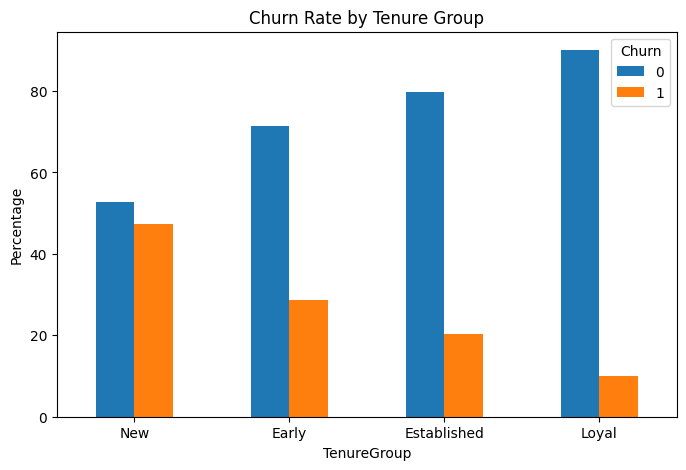

In [7]:
(
    pd.crosstab(
        train_fe["TenureGroup"],
        train_fe["Churn"],
        normalize="index"
    ) * 100
).plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Percentage")
plt.title("Churn Rate by Tenure Group")
plt.xticks(rotation=0)
plt.show()

In [9]:
def create_average_monthly_spend(df):

    df = df.copy()

    df["AvgMonthlySpend"] = np.where(
        df["tenure"] > 0,
        df["TotalCharges"] / df["tenure"],
        df["MonthlyCharges"]
    )

    return df

In [10]:
train_fe = create_average_monthly_spend(train_fe)

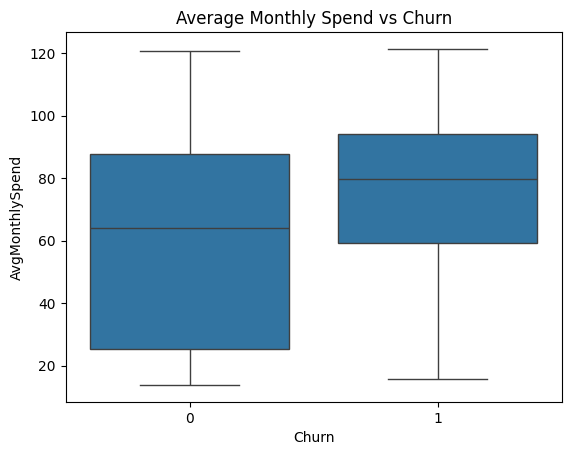

In [11]:
sns.boxplot(
    data=train_fe,
    x="Churn",
    y="AvgMonthlySpend"
)

plt.title("Average Monthly Spend vs Churn")
plt.show()

In [12]:
train_fe[
    [
        "MonthlyCharges",
        "TotalCharges",
        "AvgMonthlySpend"
    ]
].corr()

,MonthlyCharges,TotalCharges,AvgMonthlySpend
MonthlyCharges,1.000000,0.653969,0.996298
TotalCharges,0.653969,1.000000,0.653505
AvgMonthlySpend,0.996298,0.653505,1.000000


In [13]:
service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

In [14]:
def create_service_count(df):

    df = df.copy()

    df["ServiceCount"] = (
        df[service_columns] == "Yes"
    ).sum(axis=1)

    return df

In [15]:
train_fe = create_service_count(train_fe)

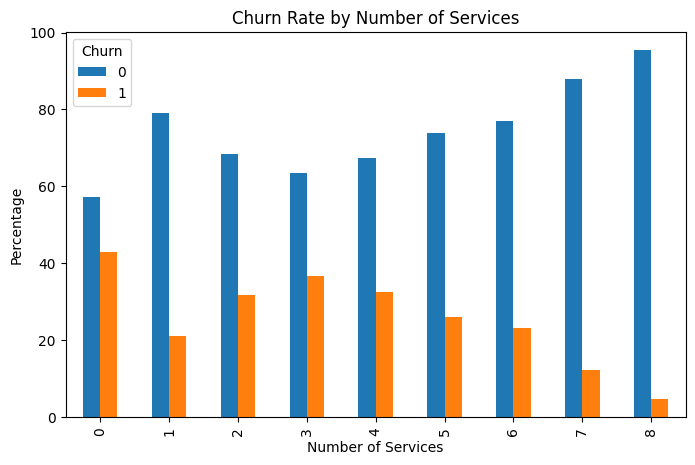

In [16]:
churn_service = (
    pd.crosstab(
        train_fe["ServiceCount"],
        train_fe["Churn"],
        normalize="index"
    ) * 100
)

churn_service.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Percentage")
plt.xlabel("Number of Services")
plt.title("Churn Rate by Number of Services")

plt.show()

In [17]:
train_fe["ContractTenure"] = (
    train_fe["Contract"].astype(str)
    + "_"
    + train_fe["TenureGroup"].astype(str)
)

In [18]:
pd.crosstab(
    train_fe["ContractTenure"],
    train_fe["Churn"],
    normalize="index"
).sort_values(
    by=1,
    ascending=False
).head(15)

Churn,0,1
ContractTenure,,
Month-to-month_New,0.489335,0.510665
Month-to-month_Early,0.617241,0.382759
Month-to-month_Established,0.672308,0.327692
Month-to-month_Loyal,0.723022,0.276978
One year_Loyal,0.869565,0.130435
One year_Established,0.893462,0.106538
One year_New,0.909091,0.090909
One year_Early,0.927711,0.072289
Two year_Loyal,0.965174,0.034826


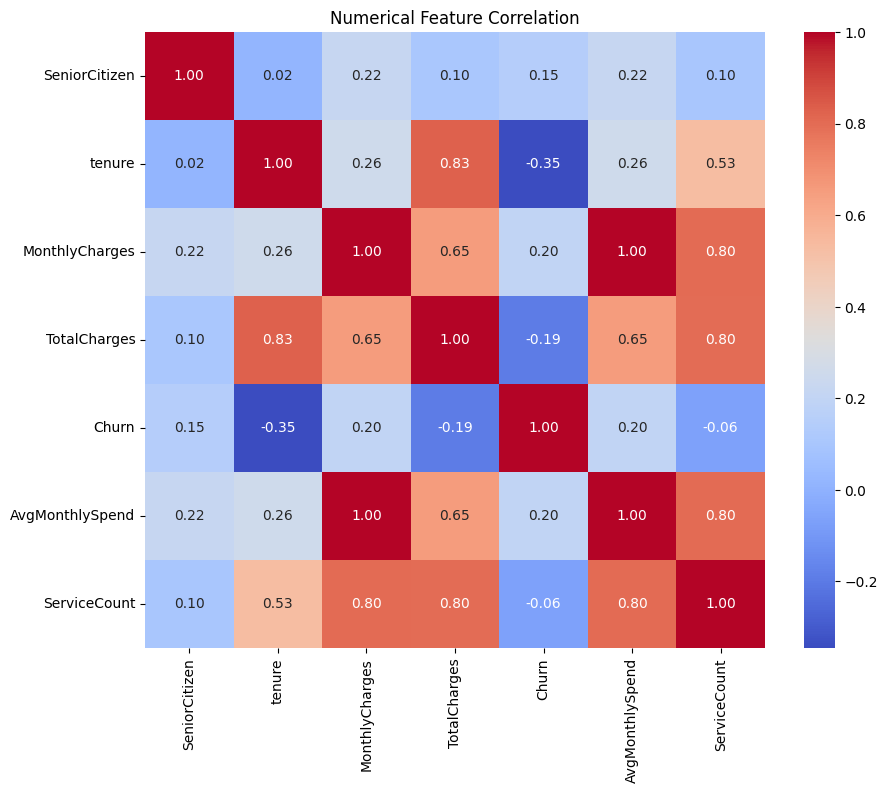

In [19]:
numeric_fe = train_fe.select_dtypes(
    include=["int64", "float64"]
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    numeric_fe.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Numerical Feature Correlation")

plt.show()

## Feature Engineering Conclusions

### Features Added

- `ServiceCount`: Number of subscribed services.
- `TenureGroup`: Customer lifecycle category based on tenure.

### Features Removed

- `customerID`: Identifier with no predictive value.
- `AvgMonthlySpend`: Highly redundant with `MonthlyCharges`
  (correlation ≈ 0.996).
- `ContractTenure`: Not included initially because some combinations
  contain relatively few observations and the interaction can potentially
  be learned from `Contract` and `tenure`.

### Final Feature Set

#### Numerical
- SeniorCitizen
- tenure
- MonthlyCharges
- TotalCharges
- ServiceCount

#### Categorical
- gender
- Partner
- Dependents
- PhoneService
- MultipleLines
- InternetService
- OnlineSecurity
- OnlineBackup
- DeviceProtection
- TechSupport
- StreamingTV
- StreamingMovies
- Contract
- PaperlessBilling
- PaymentMethod
- TenureGroup

In [21]:
numeric_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

skewness = train_df[numeric_cols].skew()

print(skewness.sort_values())

MonthlyCharges   -0.224363
tenure            0.237369
TotalCharges      0.947516
SeniorCitizen     1.822318
dtype: float64


In [22]:
train_df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,5634.0,0.163294,0.369667,0.00,0.0000,0.000,0.0000,1.00
tenure,5634.0,32.485091,24.568744,0.00,9.0000,29.000,55.0000,72.00
MonthlyCharges,5634.0,64.929961,30.138105,18.40,35.6625,70.500,90.0000,118.75
TotalCharges,5626.0,2302.604266,2279.173176,18.85,407.2750,1398.125,3838.6125,8684.80
